# 5. Instruction tuning and LoRA — real updates, tiny task

**Goal:** distinguish pretraining from instruction tuning, mask the training loss correctly, and see which weights LoRA changes. This notebook runs independently using only PyTorch; no Transformers/PEFT installation, model download, or paid service is required.

We pretrain a tiny model locally, then compare full fine-tuning and a manually implemented LoRA adapter. The task is deliberately narrow: `User: say cat` should produce `cat`. This demonstrates optimization and data formatting, not effective chatbot training.

### Definitions

| Term | Definition |
|---|---|
| Pretraining | Learning text patterns using next-token prediction over a corpus |
| Base model | Starting model before task-specific adaptation; not necessarily instruction-tuned |
| Supervised fine-tuning (SFT) | Further training using desired input/response examples |
| Chat template | Exact text/token format marking roles and turns |
| Response-only loss | Penalize response-token predictions while ignoring prompt and padding targets |
| Padding | Extra input positions added to give examples the same shape |
| EOS | End-of-sequence/response marker; here we reserve `~` as a toy EOS token |
| Frozen parameter | Weight excluded from gradient updates |
| LoRA | Low-Rank Adaptation: train small matrix factors while keeping base weights frozen |
| Rank | Intermediate dimension of the low-rank update; a capacity setting |
| Adapter | Additional trained parameters that modify a base model |
| Exact match | Fraction of generated answers exactly equal to the expected text |

We do not teach preference optimization or alignment here. To adapt a capable open model later, the same ideas need real chat templates, task-specific data, evaluation, hardware checks and a deliberate budget.

In [1]:
from pathlib import Path
import sys

# Find the lesson folder from the notebook folder, mini_llm, or repository root.
candidates = [Path.cwd(), Path.cwd() / "learning_path",
              Path.cwd() / "mini_llm" / "learning_path"]
lesson_dir = next((p.resolve() for p in candidates if (p / "lab.py").is_file()), None)
if lesson_dir is None:
    raise FileNotFoundError("Open this notebook from learning_path, mini_llm, or the repository root.")
if str(lesson_dir) not in sys.path:
    sys.path.insert(0, str(lesson_dir))

import math
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import lab

torch.set_num_threads(2)
torch.manual_seed(42)
print("Local CPU lesson | PyTorch", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


Local CPU lesson | PyTorch 2.14.1


### Step A — pretrain a tiny base locally
This is actual text training, but the base learns only 60 synthetic sentences. It has no broad world knowledge. Copies of the same pretrained weights initialize both adaptation methods.

In [2]:
import copy
base, pretrain_losses = lab.make_demo_model(steps=100, config=lab.Config(context_length=48))
full = copy.deepcopy(base)
adapted = lab.add_lora(base, rank=4)
base_snapshot = {name: value.detach().clone() for name, value in base.named_parameters()}
print("Base parameters:", sum(p.numel() for p in base.parameters()))
print("Full tuning trainable:", sum(p.numel() for p in full.parameters() if p.requires_grad))
print("LoRA trainable:", sum(p.numel() for p in adapted.parameters() if p.requires_grad))

Base parameters: 68353
Full tuning trainable: 68353
LoRA trainable: 6724


### Step B — see exactly which targets contribute to loss
Our template is `User: say <word>\nAssistant: `. The target is the word plus EOS. Input IDs are not removed: the model must read the prompt. We set **prompt targets** and **padding targets** to `-100`, PyTorch's ignored-label value.

The target at index `len(prompt)-1` is the first answer character. That off-by-one matters because targets are shifted one position ahead of inputs. Padding is on the right, so causal attention prevents earlier real tokens from reading later padding.

Prompt: 'User: say cat\nAssistant: '
Targets contributing to loss: 'cat~'


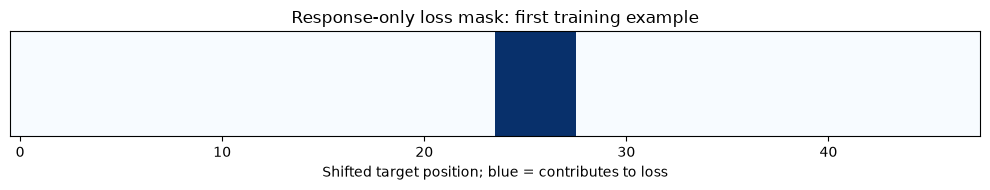

In [3]:
train_words = ["cat", "dog", "bird", "sun", "rain", "tree", "book", "fish"]
val_words = ["moon", "star"]
x, labels = lab.sft_batch(train_words, base.config.context_length)
prompt = lab.chat_prompt("cat")
active_targets = labels[0][labels[0] != -100]
print("Prompt:", repr(prompt))
print("Targets contributing to loss:", repr(lab.decode(active_targets)))
assert lab.decode(active_targets) == "cat" + lab.EOS
assert (labels[0, :len(prompt)-1] == -100).all()
fig, ax = plt.subplots(figsize=(10, 2))
ax.imshow((labels[:1] != -100).float().numpy(), cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xlabel("Shifted target position; blue = contributes to loss")
ax.set_yticks([]); ax.set_title("Response-only loss mask: first training example")
plt.tight_layout(); plt.show()

### Step C — understand the LoRA equation
A normal linear layer computes `x @ W.T + bias`. LoRA adds a trainable update:

`output = frozen_linear(x) + scale × ((x @ A.T) @ B.T)`

For `W` with shape `(output_width, input_width)`, `A` has shape `(rank, input_width)` and `B` has shape `(output_width, rank)`. The effective weight update is `scale × B @ A`.

We initialize A randomly and B to zero, so the adapter initially changes nothing. The first gradient for A can be zero because B starts at zero; this is expected. Open `LoRALinear` and `add_lora` in `lab.py` to see the implementation. Here all linear layers are adapted; embeddings and normalization stay frozen.

In [4]:
base.eval(); adapted.eval()
probe = torch.tensor([lab.encode("the cat")])
with torch.no_grad():
    torch.testing.assert_close(base(probe)[0], adapted(probe)[0])
print("Passed: zero-initialized adapter initially preserves base logits.")
frozen_before = {name: p.detach().clone() for name, p in adapted.named_parameters() if not p.requires_grad}
trainable_before = {name: p.detach().clone() for name, p in adapted.named_parameters() if p.requires_grad}
full_losses = lab.fit_sft(full, train_words, steps=180, lr=0.003)
lora_losses = lab.fit_sft(adapted, train_words, steps=180, lr=0.01)
assert all(torch.equal(before, dict(adapted.named_parameters())[name]) for name, before in frozen_before.items())
assert any(not torch.equal(before, dict(adapted.named_parameters())[name]) for name, before in trainable_before.items())
assert all(torch.equal(before, dict(base.named_parameters())[name]) for name, before in base_snapshot.items())
print("Passed: adapter parameters changed; frozen parameters and original base stayed unchanged.")

Passed: zero-initialized adapter initially preserves base logits.


Passed: adapter parameters changed; frozen parameters and original base stayed unchanged.


### Step D — evaluate generation, not just teacher-forced loss
During loss computation, each response position sees the correct preceding response characters (**teacher forcing**). During generation, the model sees its own earlier choices, so an early mistake can compound.

We report training examples separately from two held-out words. The held-out list is a fixed check for this lesson, not a final benchmark. Full tuning and LoRA use different learning rates; this is a mechanism demonstration, **not a controlled claim that either method is superior**. A failed held-out example is valuable evidence, not something to hide.

base     train    exact match: 0/8
base     held out exact match: 0/2
[('moon', 'athe the t r'), ('star', 'ainde the th')]
full SFT train    exact match: 8/8
full SFT held out exact match: 0/2
[('moon', 'raok'), ('star', 'tree')]
LoRA SFT train    exact match: 8/8
LoRA SFT held out exact match: 0/2
[('moon', 'r'), ('star', 'tree')]


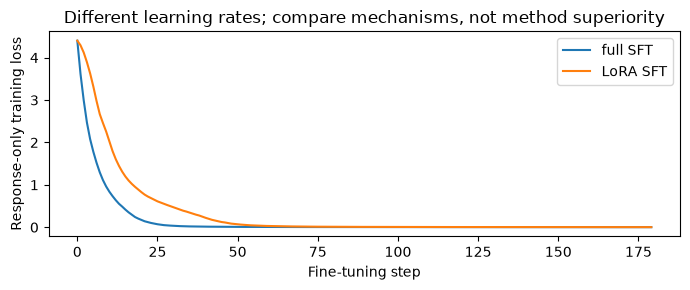

In [5]:
for name, candidate in [("base", base), ("full SFT", full), ("LoRA SFT", adapted)]:
    for split_name, words in [("train", train_words), ("held out", val_words)]:
        outputs = [lab.completion(candidate, word) for word in words]
        correct = sum(output == word for output, word in zip(outputs, words))
        print(f"{name:8s} {split_name:8s} exact match: {correct}/{len(words)}")
        if split_name == "held out": print(list(zip(words, outputs)))
plt.figure(figsize=(7, 3))
plt.plot(full_losses, label="full SFT"); plt.plot(lora_losses, label="LoRA SFT")
plt.xlabel("Fine-tuning step"); plt.ylabel("Response-only training loss")
plt.title("Different learning rates; compare mechanisms, not method superiority")
plt.legend(); plt.tight_layout(); plt.show()

### Check your understanding

Can a frozen base plus LoRA learn anything? Does exact match on training words prove general instruction following?

<details><summary>Suggested answer — try first</summary>

Yes: trainable adapter matrices change the effective computation even while base weights remain fixed. Training-word accuracy measures fit to those examples. It does not establish copying unseen words, following new instructions, or being a useful assistant.

</details>

### Your exercises
1. Change rank from 4 to 2. Calculate the change in adapter parameter count before running.
2. Explain why ignoring the prompt in the loss does not mean removing it from model input.
3. Inspect mistakes on held-out words. Are they copying errors, failure to stop, or a memorized response?
4. Plan a later experiment adapting an existing instruction model: specify its license, memory needs, tokenizer/template, dataset, baseline, evaluation and maximum compute budget before downloading or training.

**Completion criterion:** show which tensors updated, which stayed fixed, and why a low response-only loss can coexist with bad generated answers.

References: [LoRA concepts](https://huggingface.co/docs/peft/main/en/conceptual_guides/lora), [SFT and response masking](https://huggingface.co/docs/trl/main/en/sft_trainer). Next: [06 — Build an AI system](06_build_an_ai_system.ipynb).